# Are Polymarket prices calibrated?

When a market's price says **70%**, does the event happen about **70%** of the time? If it does at every price level, the market is *calibrated*: its prices can be read as honest probabilities.

This notebook answers that with the data in the local PostgreSQL database (download → normalize → snapshots → load). For every market we use its price at **1, 7 and 30 days before it closed**, never the final price, which already knows the answer.

**How to read a calibration chart**
- Each dot is a group of markets with similar prices (for example all markets priced 60–70%).
- **x** = their average price, **y** = how often the first outcome (e.g. "Yes") actually happened.
- **On the diagonal** = calibrated. **Above** = it happened more often than the price said (price too low). **Below** = price too high.
- The vertical bars are 95% intervals that resample **whole events**, because related markets (e.g. candidates in one election) move together (section 3). With fewer events in a group, the bar is longer.

In [1]:
import pandas as pd
import plotly.io as pio

from analysis.bootstrap import calibration_table_with_event_intervals, event_bootstrap
from analysis.calibration import calibration_figure, load_calibration_data, same_markets_only, scores

# Interactive charts in VS Code, plus a static image so they also show on GitHub
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 1200, 420

data = load_calibration_data()
print(f"{len(data):,} snapshots from {data['market_id'].nunique():,} markets in {data['event_id'].nunique():,} events")

20,942 snapshots from 10,768 markets in 6,345 events


## 1. The calibration curves

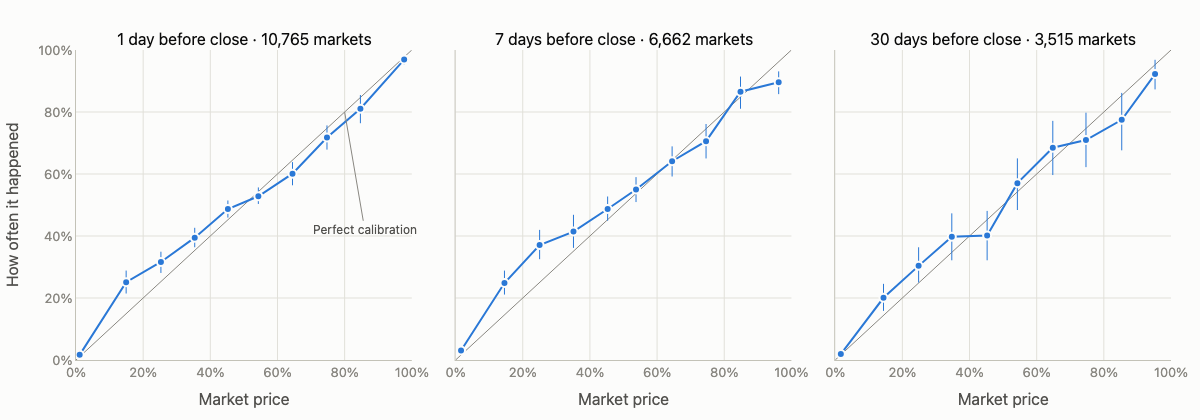

In [2]:
table = calibration_table_with_event_intervals(data)  # intervals from resampling events (section 3)
calibration_figure(table).show()

The same numbers as a table: how many markets, their average price, and how often the first outcome happened.

In [3]:
in_percent = table.assign(avg_price_pct=table["avg_price"] * 100, happened_pct=table["happened_rate"] * 100).round(1)
in_percent.pivot(index="bin_label", columns="horizon_days", values=["markets", "avg_price_pct", "happened_pct"])

markets                 avg_price_pct             happened_pct  \
horizon_days      1       7       30            1     7     30           1    
bin_label                                                                     
0–10%         3724.0  3183.0  2139.0           1.1   1.6   1.7          1.7   
10–20%         534.0   423.0   294.0          14.9  14.5  14.4         25.1   
20–30%         661.0   372.0   247.0          25.3  25.0  24.8         31.6   
30–40%         925.0   379.0   161.0          35.4  35.1  34.7         39.5   
40–50%        1388.0   624.0   147.0          45.2  45.3  45.2         48.7   
50–60%        1314.0   620.0   149.0          54.3  53.7  54.3         52.8   
60–70%         772.0   354.0   111.0          64.5  64.5  64.8         60.1   
70–80%         524.0   272.0    93.0          74.7  74.6  74.7         71.8   
80–90%         306.0   156.0    71.0          84.7  84.8  85.3         81.0   
90–100%        617.0   279.0   103.0          97.7  96.2  95.3         96.9   

                          
horizon_days    7     30  
bin_label                 
0–10%          3.0   1.9  
10–20%        24.8  20.1  
20–30%        37.1  30.4  
30–40%        41.4  39.8  
40–50%        48.7  40.1  
50–60%        55.0  57.0  
60–70%        64.1  68.5  
70–80%        70.6  71.0  
80–90%        86.5  77.5  
90–100%       89.6  92.2

## 2. How accurate are the prices overall?

Three scores per horizon:
- **Brier score**: the average of (price − outcome)². 0 is perfect; lower is better.
- **Brier skill**: how much better than always guessing the overall base rate. 1 = perfect, 0 = no better than that naive guess.
- **Calibration error**: the average gap between price and how often things happened, weighted by group size, in percentage points (0 = perfectly calibrated).

To compare horizons fairly we use **only markets that have all three snapshots**. Otherwise the 1-day group also contains thousands of short markets (e.g. sports games, which are close to coin flips the day before), and the comparison would be about *different markets*, not different horizons.

In [4]:
same = same_markets_only(data)
fair = scores(same)
fair[["base_rate", "calibration_error"]] = (fair[["base_rate", "calibration_error"]] * 100).round(1)  # in %
fair.round(3).rename(columns={"base_rate": "base_rate_%", "calibration_error": "calibration_error_%"})

,horizon_days,markets,events,base_rate_%,brier,brier_skill,calibration_error_%
0,1,3513,1205,19.2,0.046,0.701,1.2
1,7,3513,1205,19.2,0.067,0.566,1.9
2,30,3513,1205,19.2,0.089,0.424,2.0


## 3. Uncertainty that respects related markets

Markets in the same event share one underlying outcome: an election with 20 candidate markets is closer to *one* piece of evidence than to 20. Standard confidence intervals treat every market as independent, so they come out too narrow. Here we use an **event-level bootstrap**: draw events with replacement (each draw brings all of that event's markets), recompute the statistics, repeat 1,000 times, and take the middle 95% of the results.

Two statistics, per horizon:
- **Calibration gap**: the average distance between price and how often things happened (as in section 2).
- **Calibration slope** *b*, from fitting P(happened) = sigmoid(*a* + *b* · logit(price)). *b* = 1 means honest prices; **b < 1 means reality is closer to 50% than the prices: prices are too extreme**. If the whole 95% interval is below 1, that holds even with related markets accounted for.

The slope is fitted on prices between **5% and 95%** only. Near-certain prices sit at the edge of the logit scale, and how they are squashed there moved the slope a lot in testing (on long-running markets from 0.97 to 1.21), so they would decide the answer instead of the data. The calibration gap still uses every market.

For comparison, the last column repeats the interval as if every market were independent.

In [5]:
def uncertainty(table):
    by_event, _ = event_bootstrap(table)
    by_market, _ = event_bootstrap(table, by_event=False)
    interval = lambda low, high, scale=1, digits=2: [f"[{l * scale:.{digits}f}, {h * scale:.{digits}f}]" for l, h in zip(low, high)]
    verdict = ["too extreme" if high < 1 else "too timid" if low > 1 else "no clear evidence"
               for low, high in zip(by_event["slope_low"], by_event["slope_high"])]
    # .to_numpy(): plain values, so pandas doesn't try to line rows up by their old labels
    return pd.DataFrame({
        "markets": by_event["markets"].to_numpy(), "events": by_event["units"].to_numpy(),
        "gap_pts": (by_event["calibration_error"] * 100).round(1).to_numpy(),
        "gap_95%": interval(by_event["error_low"], by_event["error_high"], 100, 1),
        "slope (5-95% prices)": by_event["slope"].round(2).to_numpy(),
        "slope_95%": interval(by_event["slope_low"], by_event["slope_high"]),
        "prices are": verdict,
        "slope_95% if independent": interval(by_market["slope_low"], by_market["slope_high"]),
    }, index=pd.Index(by_event["horizon_days"].to_numpy(), name="days before close"))

print("All markets")
uncertainty(data)

All markets


,markets,events,gap_pts,gap_95%,slope (5-95% prices),slope_95%,prices are,slope_95% if independent
days before close,,,,,,,,
1,10765,6345,2.7,"[2.1, 3.4]",0.74,"[0.68, 0.79]",too extreme,"[0.68, 0.79]"
7,6662,3191,3.3,"[2.8, 4.3]",0.72,"[0.66, 0.80]",too extreme,"[0.66, 0.79]"
30,3515,1205,2.0,"[1.4, 3.2]",0.82,"[0.71, 0.93]",too extreme,"[0.72, 0.92]"


In [6]:
print("Only markets with all three snapshots (the fair comparison between horizons)")
uncertainty(same)

Only markets with all three snapshots (the fair comparison between horizons)


,markets,events,gap_pts,gap_95%,slope (5-95% prices),slope_95%,prices are,slope_95% if independent
days before close,,,,,,,,
1,3513,1205,1.2,"[0.9, 2.1]",0.97,"[0.80, 1.17]",no clear evidence,"[0.83, 1.11]"
7,3513,1205,1.9,"[1.5, 3.0]",0.90,"[0.78, 1.04]",no clear evidence,"[0.78, 1.03]"
30,3513,1205,2.0,"[1.4, 3.2]",0.82,"[0.70, 0.93]",too extreme,"[0.72, 0.92]"


## 4. What we found

*Numbers from the data as of 2026-10-20: 10,768 resolved markets with snapshots, ≥ $1M volume.*

1. **Polymarket is broadly well calibrated.** On the 3,513 markets with all three snapshots, the average gap between price and reality is 1.2, 1.9 and 2.0 percentage points at 1, 7 and 30 days before close, with 95% intervals of [0.9, 2.1], [1.5, 3.0] and [1.4, 3.2] (section 3).
2. **Prices get more accurate as the close approaches.** On those same markets the Brier score falls from 0.089 (30 days) to 0.067 (7 days) to 0.046 (1 day), and skill rises from 0.424 to 0.566 to 0.701 (section 2).
3. **Overall, prices are too extreme.** Across all markets the calibration slope is 0.74 [0.68, 0.79] one day before close, 0.72 [0.66, 0.80] at 7 days and 0.82 [0.71, 0.93] at 30 days: every interval is below 1, even with related markets resampled together. In the raw numbers: one day before close, markets priced 10–20% averaged 14.9% but happened 25.1% of the time (534 markets); every price group below 50% happened more often than its price, and every group above 50% less often. This is the reverse of the classic *favorite–longshot bias*, where unlikely outcomes are overpriced.
4. **Close to the end, the bias comes mostly from shorter markets.** On the long-running markets (all three snapshots) it is clear only 30 days out (slope 0.82 [0.70, 0.93]); at 1 and 7 days the intervals include 1 (0.97 [0.80, 1.17] and 0.90 [0.78, 1.04]). Few long-running markets are still uncertain a day before close, so those intervals are wide, but the estimates also sit near 1. The difference points at markets that are open only days or weeks, such as sports games, which is what a topic split should test next.
5. **Related markets matter less than feared.** Resampling whole events widens the intervals only slightly compared with treating every market as independent (e.g. [0.80, 1.17] instead of [0.83, 1.11]), and none of the conclusions change.

## Caveats

- **Which markets:** only resolved markets with ≥ $1M volume, ending from July 2020, open at least 1 day. Smaller markets could behave differently.
- **Related markets:** handled by resampling whole events (section 3). Events are Polymarket's own grouping; related markets in *different* events (e.g. two elections on the same night) are still treated as independent.
- **"Outcome" means the first listed outcome**, e.g. "Yes", or the first team in "Team A vs Team B". Every market has two sides, so the chart is the same data seen from one side.
- **No topic split yet:** Polymarket leaves `category` empty for almost all markets, so we can't yet compare e.g. sports vs politics. That is the obvious next question, especially for finding 3.
- **Prices aren't trades:** we use the price-history API's price; a real trader would also pay the bid–ask spread and fees.